# Teacher Survey Analysis

This notebook examines teacher profiles, familiarity with computational
thinking, technology experience, teaching practices, attitudes,
teaching challenges, and environmental concerns.

The analysis uses the cleaned teacher survey. Unresolved duplicate
candidates remain included and results are labeled provisional.

Confidence questions containing "After completing the summit" are
reported separately. Their timing must be verified before interpreting
them as baseline confidence or evidence of improvement.

In [1]:
%pip install pandas openpyxl matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


## 1. Load the Teacher Data and Prepare Output Folders

Load the Cleaned Data sheet while preserving explicit text responses
such as "None" and "NA".

Save teacher outputs in dedicated folders.

In [2]:
from pathlib import Path
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display


current = Path.cwd().resolve()

ROOT = next(
    (
        folder
        for folder in [current, *current.parents]
        if (folder / "data" / "cleaned").is_dir()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError("Cannot locate data/cleaned.")

CLEANED = ROOT / "data" / "cleaned"
TABLES = ROOT / "outputs" / "tables" / "teachers"
FIGURES = ROOT / "outputs" / "figures" / "teachers"

for folder in [TABLES, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)

df = pd.read_excel(
    CLEANED / "teachers_pre_event_cleaned.xlsx",
    sheet_name="Cleaned Data",
    keep_default_na=False,
    na_values=[""],
)

assert df["response_id"].notna().all()
assert df["response_id"].is_unique

original_n = len(df)
tables = {}

PURPLE = "#6F42A6"
ORANGE = "#E8913A"

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

print("Teacher submissions:", len(df))
print("Columns:", df.shape[1])

Teacher submissions: 55
Columns: 57


## 2. Standardize Categories and Identify Review Issues

Normalize spacing and preserve original written responses.

Apply only verified exclusions. Recheck repeated names and identify
schools associated with multiple cluster values.

Missing school information does not automatically exclude a teacher
from other analyses.

In [3]:
def normalize_text(value):
    if pd.isna(value):
        return pd.NA

    value = unicodedata.normalize("NFKC", str(value))
    value = re.sub(r"\s+", " ", value).strip()

    return value if value else pd.NA


# Add IDs only after confirming which submissions should be excluded.
CONFIRMED_EXCLUDE_IDS = set()

unknown_ids = CONFIRMED_EXCLUDE_IDS - set(df["response_id"])

if unknown_ids:
    raise ValueError(f"Unknown response IDs: {unknown_ids}")

tables["excluded_submissions"] = df.loc[
    df["response_id"].isin(CONFIRMED_EXCLUDE_IDS),
    ["response_id", "source_excel_row"],
].copy()

df = df.loc[
    ~df["response_id"].isin(CONFIRMED_EXCLUDE_IDS)
].copy()

category_columns = [
    "school_name",
    "position",
    "grades_taught",
    "gender",
    "teaching_experience",
    "subject_areas",
    "attendance_days",
    "prior_devcon",
    "project_facilitation",
    "climate_familiarity",
]

for column in category_columns:
    df[column] = df[column].map(normalize_text)

# Standardize different dash characters in experience categories.
df["teaching_experience"] = (
    df["teaching_experience"]
    .astype("string")
    .str.replace(r"[-‐‑–—]", "–", regex=True)
)

for column in ["prior_devcon", "project_facilitation"]:
    values = df[column].astype("string").str.casefold()
    unexpected = values.notna() & ~values.isin(["yes", "no"])

    if unexpected.any():
        raise ValueError(
            f"Unexpected responses in {column}: "
            f"{values[unexpected].unique()}"
        )

    df[column] = values.map({"yes": "Yes", "no": "No"})

name_key = (
    df["first_name"].map(normalize_text).astype("string").str.casefold()
    + "|"
    + df["last_name"].map(normalize_text).astype("string").str.casefold()
)

df["possible_duplicate"] = (
    name_key.notna()
    & name_key.duplicated(keep=False)
)

df["school_key"] = (
    df["school_name"].astype("string").str.casefold()
)

df["school_cluster"] = pd.to_numeric(
    df["school_cluster"],
    errors="raise",
).astype("Int64")

df["missing_school"] = (
    df["school_name"].isna()
    | df["school_cluster"].isna()
)

cluster_counts = (
    df.dropna(subset=["school_key", "school_cluster"])
    .groupby("school_key")["school_cluster"]
    .nunique()
)

conflicting_schools = set(
    cluster_counts[cluster_counts > 1].index
)

df["school_cluster_inconsistent"] = df["school_key"].isin(
    conflicting_schools
)

review_columns = [
    "response_id",
    "timestamp",
    "first_name",
    "last_name",
    "school_name",
    "school_cluster",
]

tables["duplicate_candidates"] = df.loc[
    df["possible_duplicate"], review_columns
].copy()

tables["school_review"] = df.loc[
    df["missing_school"] | df["school_cluster_inconsistent"],
    review_columns,
].copy()

PROVISIONAL = bool(df["possible_duplicate"].any())

display(tables["duplicate_candidates"])
display(tables["school_review"])

,response_id,timestamp,first_name,last_name,school_name,school_cluster
34,T0035,2026-08-11 06:59:30.251,LEAH,PADILLA,Rizal High School,5
36,T0037,2026-08-11 10:53:46.837,LEAH,PADILLA,Rizal High School,5


,response_id,timestamp,first_name,last_name,school_name,school_cluster
0,T0001,2026-08-07 19:41:09.597,Adelina,Alcantara,NaN,<NA>
1,T0002,2026-08-10 11:07:50.399,Mary Grace D.,Arellano,Rizal High School,2
7,T0008,2026-08-14 08:08:16.375,Aliza,Vasquez,Manggahan High School,9
34,T0035,2026-08-11 06:59:30.251,LEAH,PADILLA,Rizal High School,5
36,T0037,2026-08-11 10:53:46.837,LEAH,PADILLA,Rizal High School,5
37,T0038,2026-08-11 13:42:14.752,Nico,Risos,NaN,<NA>
51,T0052,2026-08-13 15:27:47.084,EDDIE,CARLET KIDS,Manggahan High School,9
53,T0054,2026-08-14 08:35:45.145,Lady Reymelyn Carla,Occidental,NaN,<NA>
54,T0055,2026-08-18 10:42:24.709,Elizah Michaela,Macaraig,Manggahan High School,1


### Data-Quality Findings

All 55 submissions were retained. Two records were flagged as possible
repeated submissions, but neither was removed because the duplicate
decision remains unresolved.

Three submissions lack school names or cluster information. Two schools
also have inconsistent reported cluster assignments: Rizal High School
has clusters 2 and 5, while Manggahan High School has clusters 1 and 9.

These discrepancies require verification before school-cluster analysis.
They do not automatically invalidate the respondents' other answers.

The results below describe submissions rather than a confirmed count
of unique respondents and remain provisional.

## 3. Validate Survey Scales

Standardize capitalization using the actual response categories.

Keep familiarity, technology use, teaching frequency, and confidence
as separate scales. Do not treat them as interchangeable measurements.

Validate the five numeric attitude questions against ratings 1–5.
Unexpected categories or ratings must be reviewed before continuing.

In [4]:
FAMILIARITY = {
    "familiarity_ct": "Computational thinking",
    "familiarity_flowcharts": "Flowcharting",
    "familiarity_block_coding": "Block-based coding",
    "familiarity_text_coding": "Text-based coding",
    "familiarity_matatag": "MATATAG CT competencies",
}

TECHNOLOGY_USE = {
    "usage_hour_of_code": "Hour of Code/AI",
    "usage_scratch": "Scratch",
    "usage_microbit": "Micro:bit",
    "usage_arduino": "Arduino",
    "usage_ai": "Artificial intelligence",
    "usage_climate_kit": "Climate Action Kit",
}

FREQUENCY = {
    "frequency_ct": "Explicitly teach CT",
    "frequency_flowcharts": "Use flowcharts",
    "frequency_coding": "Facilitate coding",
    "frequency_pbl": "Use PBL",
    "frequency_real_world": "Connect technology to real-world problems",
}

CONFIDENCE = {
    "after_summit_conf_ct": "Explain CT",
    "after_summit_conf_flowcharts": "Teach flowcharting",
    "after_summit_conf_coding": "Facilitate coding",
    "after_summit_conf_lesson_design": "Design CT-integrated lessons",
    "after_summit_conf_matatag": "Integrate CT into MATATAG",
    "after_summit_conf_assessment": "Assess CT skills",
    "after_summit_conf_climate": "Connect CT to climate topics",
    "after_summit_conf_inclusion": "Adapt lessons to learning needs",
    "after_summit_conf_collaboration": "Facilitate collaborative problem-solving",
}

ATTITUDES = {
    "ct_value_belief": "CT is valuable for all students",
    "environment_tech_belief": "Technology supports environmental solutions",
    "matatag_opportunities": "Identify CT opportunities in MATATAG",
    "integration_intention": "Intend to integrate CT this school year",
    "teaching_identity": "See oneself as able to teach CT and coding",
}

FAMILIARITY_ORDER = [
    "Not familiar",
    "Slightly familiar",
    "Somewhat familiar",
    "Familiar",
    "Very familiar",
]

USE_ORDER = [
    "Never used",
    "Used personally",
    "Used with students",
]

FREQUENCY_ORDER = [
    "Never",
    "Rarely",
    "Sometimes",
    "Often",
]

# These are the confidence categories observed in the supplied data.
CONFIDENCE_ORDER = [
    "Not confident at all",
    "Slightly confident",
    "Moderately confident",
    "Confident",
]


def standardize_scale(columns, ordered_labels):
    lookup = {
        label.casefold(): label
        for label in ordered_labels
    }

    for column in columns:
        original = df[column].map(normalize_text)
        keys = original.astype("string").str.casefold()

        unexpected = keys.notna() & ~keys.isin(lookup)

        if unexpected.any():
            display(
                df.loc[unexpected, ["response_id", column]]
            )
            raise ValueError(
                f"Review unexpected categories in {column}."
            )

        df[column] = keys.map(lookup)


standardize_scale(FAMILIARITY, FAMILIARITY_ORDER)
standardize_scale(TECHNOLOGY_USE, USE_ORDER)
standardize_scale(FREQUENCY, FREQUENCY_ORDER)
standardize_scale(CONFIDENCE, CONFIDENCE_ORDER)

for column in ATTITUDES:
    original = df[column]
    numeric = pd.to_numeric(original, errors="coerce")

    invalid = original.notna() & ~numeric.isin([1, 2, 3, 4, 5])

    if invalid.any():
        display(df.loc[invalid, ["response_id", column]])
        raise ValueError(f"Invalid ratings in {column}.")

    df[column] = numeric.astype("Int64")

tables["missing_answers"] = (
    pd.DataFrame({
        "column": df.columns,
        "missing_count": df.isna().sum().to_numpy(),
        "missing_percent": (
            df.isna().mean().mul(100).to_numpy()
        ),
    })
    .sort_values("missing_count", ascending=False)
)

display(tables["missing_answers"].head(12))

,column,missing_count,missing_percent
52,accommodation_needs,12,21.818182
5,school_name,3,5.454545
6,school_cluster,3,5.454545
57,school_key,3,5.454545
1,source_excel_row,0,0.000000
2,timestamp,0,0.000000
3,first_name,0,0.000000
7,attendance_days,0,0.000000
8,position,0,0.000000
4,last_name,0,0.000000


## 4. Define Table and Figure Functions

Calculate percentages from valid responses to each question.

Tables include valid and missing counts. Figures are saved at 300 DPI.

For scale questions, use ordered stacked bars and retain the response
distribution rather than combining unrelated questions into one score.

In [5]:
def save_figure(fig, filename, note=""):
    status = (
        "Provisional submission-level results; duplicate review pending."
        if PROVISIONAL
        else "Submission-level results after recorded exclusions."
    )

    fig.text(
        0.01,
        0.01,
        status + (" " + note if note else ""),
        fontsize=8,
        color="#555555",
    )

    fig.tight_layout(rect=[0, 0.09, 1, 1])

    fig.savefig(
        FIGURES / filename,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)


def frequency_table(series, order=None):
    valid = series.dropna()
    counts = valid.value_counts()

    if order is not None:
        extras = [
            value for value in counts.index
            if value not in order
        ]

        counts = counts.reindex(
            list(order) + extras,
            fill_value=0,
        )

    table = counts.rename_axis(
        "category"
    ).reset_index(name="count")

    table["percent"] = (
        table["count"] / len(valid) * 100
        if len(valid)
        else np.nan
    )

    table["valid_n"] = len(valid)
    table["missing_n"] = int(series.isna().sum())

    return table


def horizontal_bar(table, title, filename, note=""):
    if table.empty or not table["percent"].notna().any():
        print("No valid data:", title)
        return

    fig, ax = plt.subplots(
        figsize=(10, max(4, len(table) * 0.48))
    )

    positions = np.arange(len(table))

    bars = ax.barh(
        positions,
        table["percent"],
        color=PURPLE,
    )

    ax.set_yticks(positions)
    ax.set_yticklabels(table["category"].astype(str))
    ax.invert_yaxis()

    ax.set_title(title)
    ax.set_xlabel("Percentage of valid responses")
    ax.set_ylabel("")

    ax.set_xlim(
        0,
        max(20, float(table["percent"].max()) * 1.3),
    )

    ax.bar_label(
        bars,
        labels=[
            f"{percent:.1f}% (n={count})"
            for percent, count in zip(
                table["percent"], table["count"]
            )
        ],
        padding=4,
        fontsize=9,
    )

    save_figure(fig, filename, note)


def scale_chart(mapping, order, title, filename, table_key, note=""):
    rows = []

    for column, label in mapping.items():
        valid = df[column].dropna()

        counts = valid.value_counts().reindex(
            order,
            fill_value=0,
        )

        for category in order:
            rows.append({
                "column": column,
                "item": label,
                "category": category,
                "count": int(counts[category]),
                "percent": (
                    counts[category] / len(valid) * 100
                    if len(valid)
                    else np.nan
                ),
                "valid_n": len(valid),
                "missing_n": int(df[column].isna().sum()),
            })

    table = pd.DataFrame(rows)
    tables[table_key] = table

    percentages = (
        table.pivot(
            index="item",
            columns="category",
            values="percent",
        )
        .reindex(
            index=list(mapping.values()),
            columns=order,
        )
    )

    valid_counts = (
        table.drop_duplicates("item")
        .set_index("item")["valid_n"]
        .reindex(percentages.index)
    )

    fig, ax = plt.subplots(
        figsize=(12, max(4.5, len(mapping) * 0.65))
    )

    left = np.zeros(len(percentages))

    colors = sns.color_palette(
        "Purples",
        n_colors=len(order) + 1,
    )[1:]

    for category, color in zip(order, colors):
        widths = percentages[category].fillna(0).to_numpy()

        ax.barh(
            np.arange(len(percentages)),
            widths,
            left=left,
            label=str(category),
            color=color,
        )

        left += widths

    ax.set_yticks(np.arange(len(percentages)))
    ax.set_yticklabels([
        f"{label} (n={int(n)})"
        for label, n in zip(percentages.index, valid_counts)
    ])

    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("Percentage of valid responses")
    ax.set_title(title)

    ax.legend(
        title="Response",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )

    save_figure(fig, filename, note)

## 5. Describe Teacher Profiles and Prior Experience

Summarize position, grades taught, teaching experience, subject areas,
previous DEVCON attendance, and project-facilitation experience.

Subject areas are reported as entered. A response listing multiple
subjects is not automatically interpreted as a single subject.

Attendance-day responses represent stated attendance plans, not verified
event attendance.

,category,count,percent,valid_n,missing_n
0,Teacher,53,96.363636,55,0
1,ICT Coordinator,2,3.636364,55,0


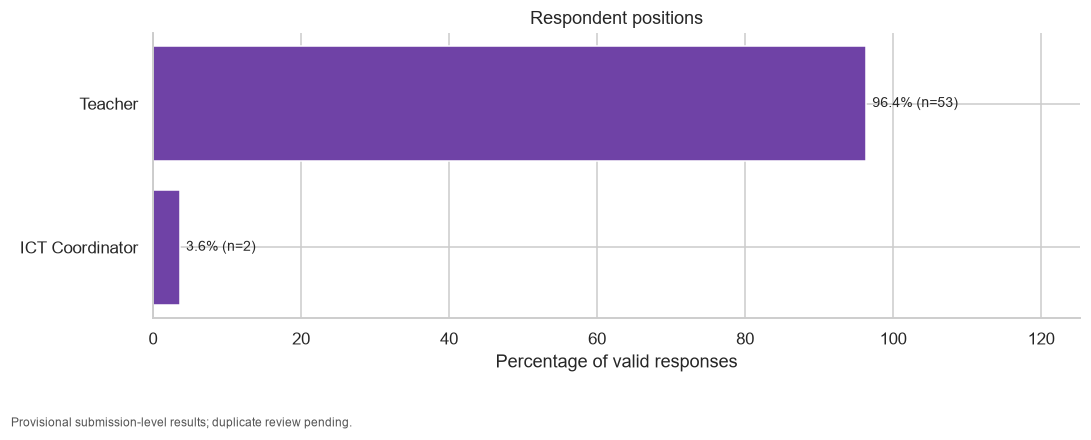

,category,count,percent,valid_n,missing_n
0,Grade 5,9,16.363636,55,0
1,Grade 6,14,25.454545,55,0
2,Grade 7,13,23.636364,55,0
3,Grade 8,12,21.818182,55,0
4,Grade 9,4,7.272727,55,0
5,Not applicable,3,5.454545,55,0


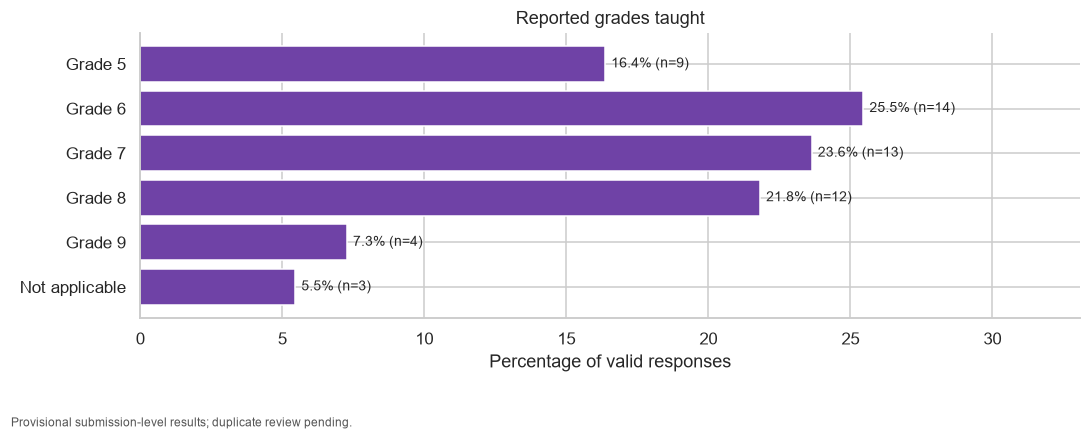

,category,count,percent,valid_n,missing_n
0,1–3 years,4,7.272727,55,0
1,4–7 years,6,10.909091,55,0
2,8–15 years,28,50.909091,55,0
3,More than 15 years,17,30.909091,55,0


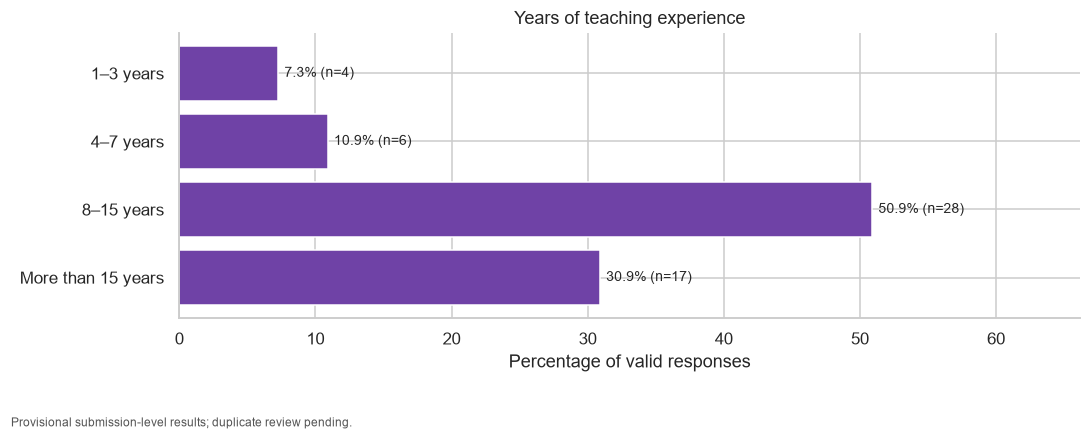

,category,count,percent,valid_n,missing_n
0,Science,48,87.272727,55,0
1,TLE,2,3.636364,55,0
2,AP,1,1.818182,55,0
3,MAPEH,1,1.818182,55,0
4,Filipino,1,1.818182,55,0
5,Science 8 and Values Education,1,1.818182,55,0
6,Art,1,1.818182,55,0


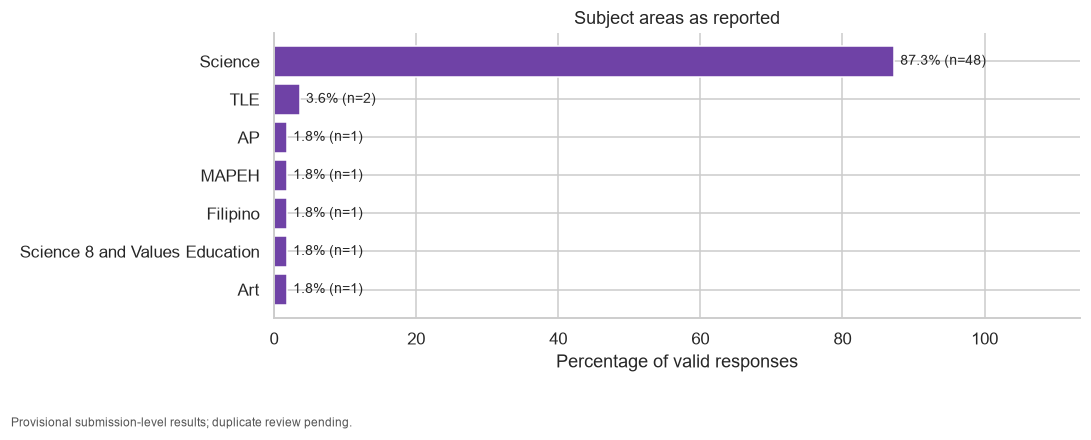

,category,count,percent,valid_n,missing_n
0,Yes,2,3.636364,55,0
1,No,53,96.363636,55,0


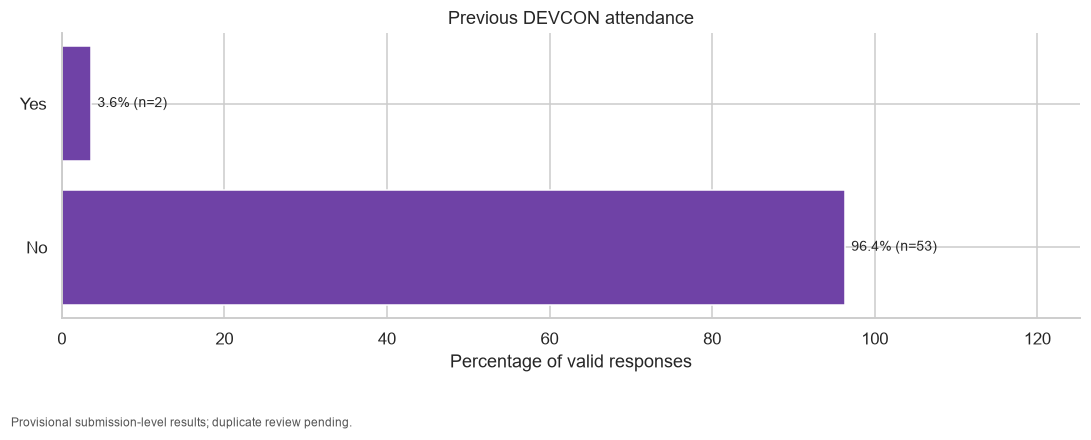

,category,count,percent,valid_n,missing_n
0,Yes,6,10.909091,55,0
1,No,49,89.090909,55,0


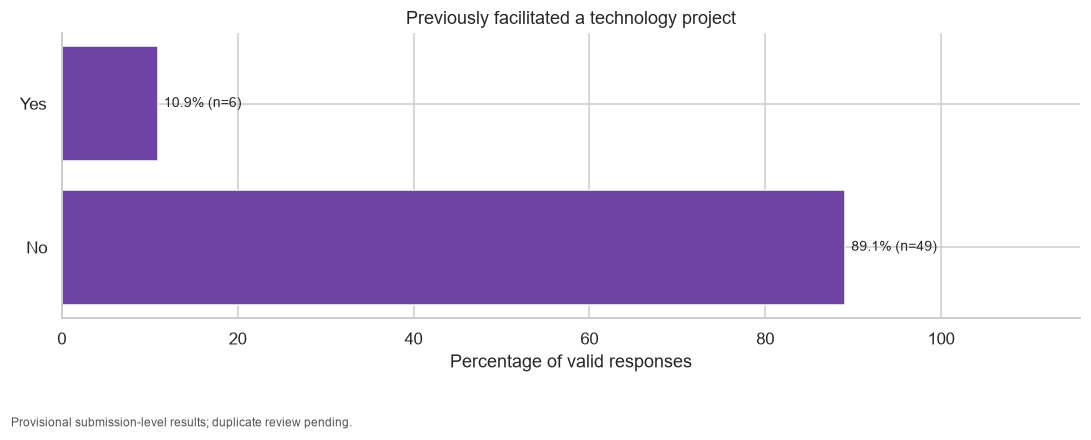

,category,count,percent,valid_n,missing_n
0,Not familiar,0,0.000000,55,0
1,Heard about it,6,10.909091,55,0
2,Somewhat familiar,21,38.181818,55,0
3,Very familiar,28,50.909091,55,0


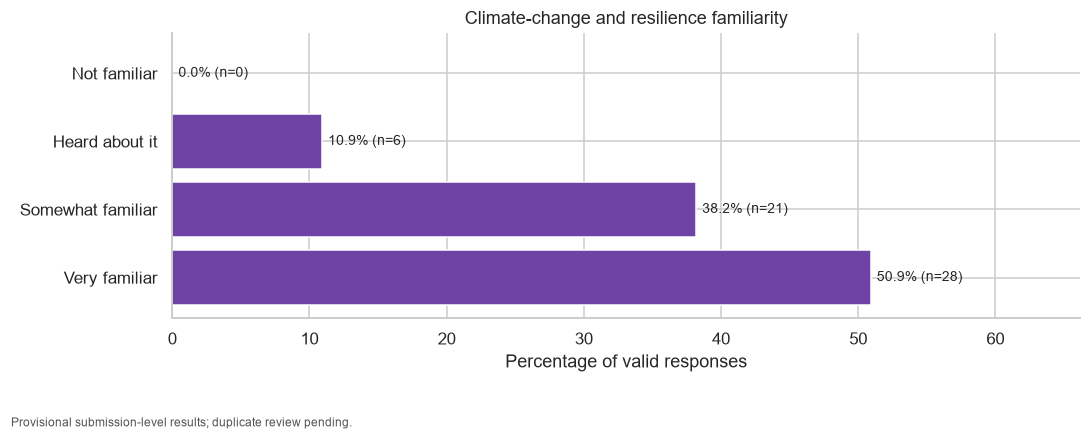

In [6]:
profile_specs = [
    (
        "position",
        ["Teacher", "ICT Coordinator"],
        "Respondent positions",
    ),
    (
        "grades_taught",
        [
            "Grade 5", "Grade 6", "Grade 7",
            "Grade 8", "Grade 9", "Not applicable",
        ],
        "Reported grades taught",
    ),
    (
        "teaching_experience",
        [
            "1–3 years",
            "4–7 years",
            "8–15 years",
            "More than 15 years",
        ],
        "Years of teaching experience",
    ),
    (
        "subject_areas",
        None,
        "Subject areas as reported",
    ),
    (
        "prior_devcon",
        ["Yes", "No"],
        "Previous DEVCON attendance",
    ),
    (
        "project_facilitation",
        ["Yes", "No"],
        "Previously facilitated a technology project",
    ),
    (
        "climate_familiarity",
        [
            "Not familiar",
            "Heard about it",
            "Somewhat familiar",
            "Very familiar",
        ],
        "Climate-change and resilience familiarity",
    ),
]

for column, order, title in profile_specs:
    table = frequency_table(df[column], order)
    tables[column] = table

    display(table)

    horizontal_bar(
        table,
        title,
        f"teachers_{column}.png",
    )

tables["school_distribution"] = frequency_table(df["school_name"])
tables["gender_distribution"] = frequency_table(df["gender"])
tables["attendance_plans"] = frequency_table(df["attendance_days"])

### Respondent Profile and Previous Experience

Of the 55 submissions, 53 (96.4%) identified the respondent as a teacher
and two (3.6%) as an ICT coordinator.

Most submissions came from experienced educators: 28 (50.9%) reported
8–15 years of teaching experience, and 17 (30.9%) reported more than
15 years. Together, these categories represented 81.8% of submissions.

Science was the most common subject-area response, appearing as the
standalone answer in 48 submissions (87.3%). One additional submission
listed Science 8 and Values Education. The results therefore mainly
reflect a science-oriented respondent group rather than an even
representation of subject areas.

Despite substantial general teaching experience, 49 submissions
(89.1%) reported no previous facilitation of a coding, robotics, or
technology project. Only two (3.6%) reported previous DEVCON attendance.

This suggests that general teaching experience should not be assumed
to imply prior experience facilitating technology projects.

## 6. Examine Familiarity with Computational-Thinking Concepts

Compare familiarity with computational thinking, flowcharting,
block-based coding, text-based coding, and MATATAG CT competencies.

The figure displays self-reported familiarity. It does not measure
objective teaching competence.

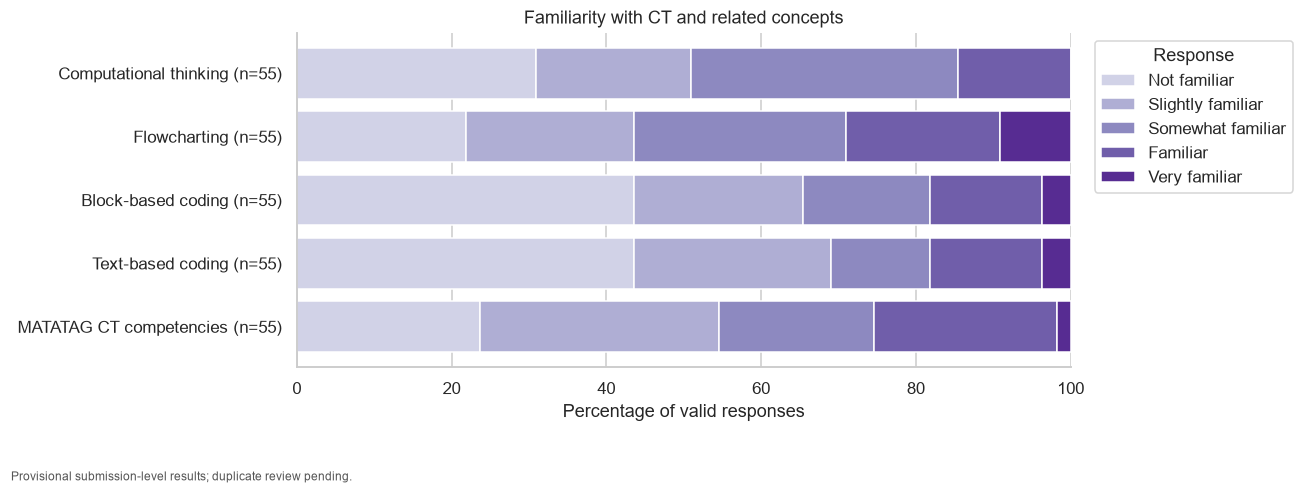

In [7]:
scale_chart(
    mapping=FAMILIARITY,
    order=FAMILIARITY_ORDER,
    title="Familiarity with CT and related concepts",
    filename="teachers_concept_familiarity.png",
    table_key="concept_familiarity",
)

### Familiarity with CT and Related Concepts

The familiarity chart shows that responses were concentrated in the
lower and middle familiarity categories.

For computational thinking, most responses fell between "Not familiar"
and "Somewhat familiar", with no responses in "Very familiar".

Block-based and text-based coding also showed substantial concentrations
in the "Not familiar" and "Slightly familiar" categories.

These patterns suggest a need for introductory explanations and guided
practice. However, the responses measure perceived familiarity and
should not be interpreted as objective assessments of competence.

## 7. Examine Technology Experience

Compare whether teachers have never used each technology, used it
personally, or used it with students.

The categories represent the recorded answers. "Used with students"
is not automatically recoded into another response category.

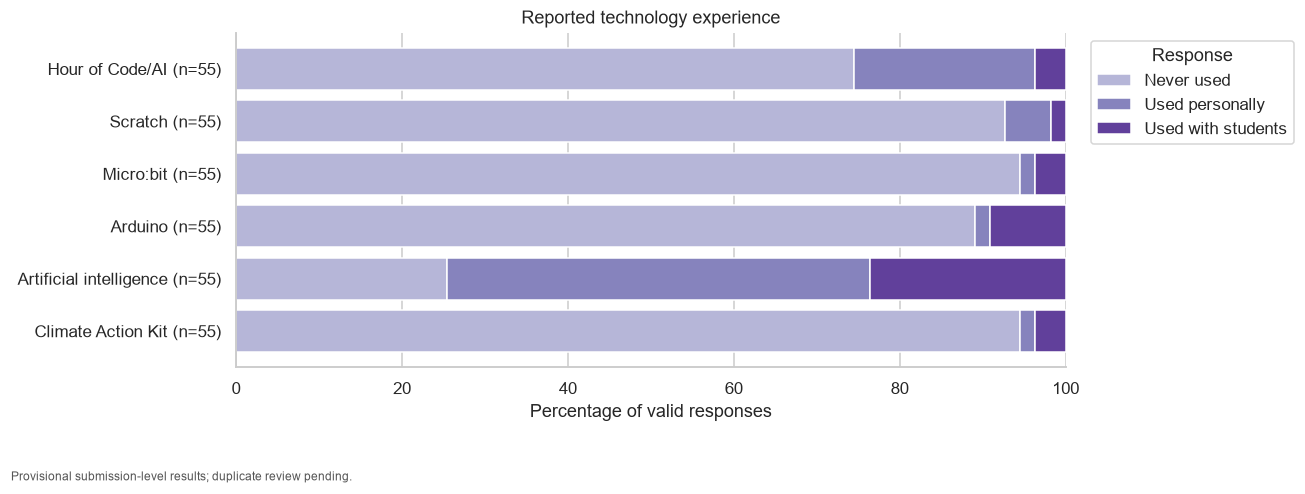

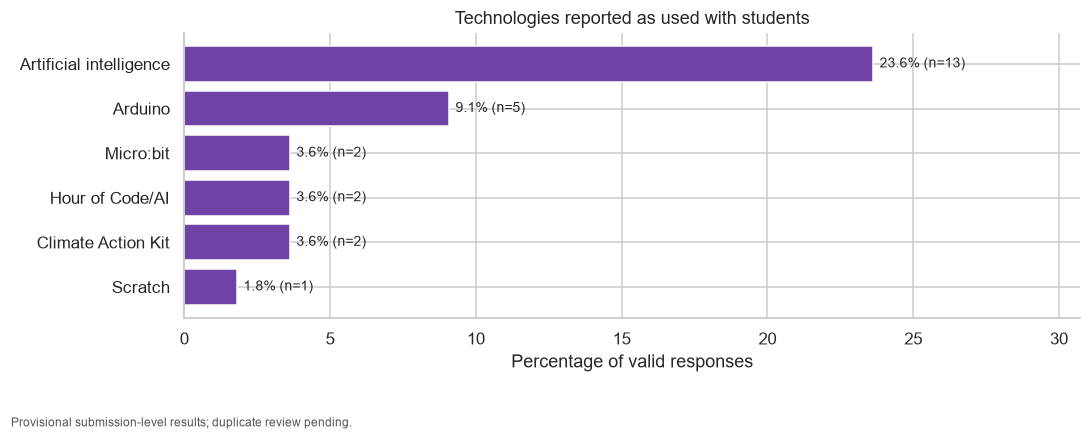

In [8]:
scale_chart(
    mapping=TECHNOLOGY_USE,
    order=USE_ORDER,
    title="Reported technology experience",
    filename="teachers_technology_experience.png",
    table_key="technology_experience",
)

classroom_use_rows = []

for column, label in TECHNOLOGY_USE.items():
    valid = df[column].dropna()

    count = int(valid.eq("Used with students").sum())

    classroom_use_rows.append({
        "category": label,
        "count": count,
        "percent": count / len(valid) * 100 if len(valid) else np.nan,
        "valid_n": len(valid),
        "missing_n": int(df[column].isna().sum()),
    })

tables["classroom_technology_use"] = (
    pd.DataFrame(classroom_use_rows)
    .sort_values("percent", ascending=False)
)

horizontal_bar(
    tables["classroom_technology_use"],
    "Technologies reported as used with students",
    "teachers_classroom_technology_use.png",
)

### Technology Experience Findings

Artificial intelligence had the highest reported classroom use:
13 of 55 submissions (23.6%) indicated that it had been used with students.

Classroom use of other listed technologies was less common:

| Technology | Used with students | Percentage |
|---|---:|---:|
| Artificial intelligence | 13 | 23.6% |
| Arduino | 5 | 9.1% |
| Micro:bit | 2 | 3.6% |
| Hour of Code/AI | 2 | 3.6% |
| Climate Action Kit | 2 | 3.6% |
| Scratch | 1 | 1.8% |

The results suggest that classroom exposure varies considerably across
technologies. Training should not assume that respondents have already
used programming or physical-computing tools with students.

These figures describe reported use, not the frequency or quality of
classroom implementation.

## 8. Examine Teaching Practices and Attitudes

Compare the reported frequency of CT-related teaching practices.

Display the five attitude statements separately using their original
1–5 ratings. Verbal rating anchors should be checked against the
questionnaire before labeling ratings as agreement or disagreement.

No overall attitude score is calculated.

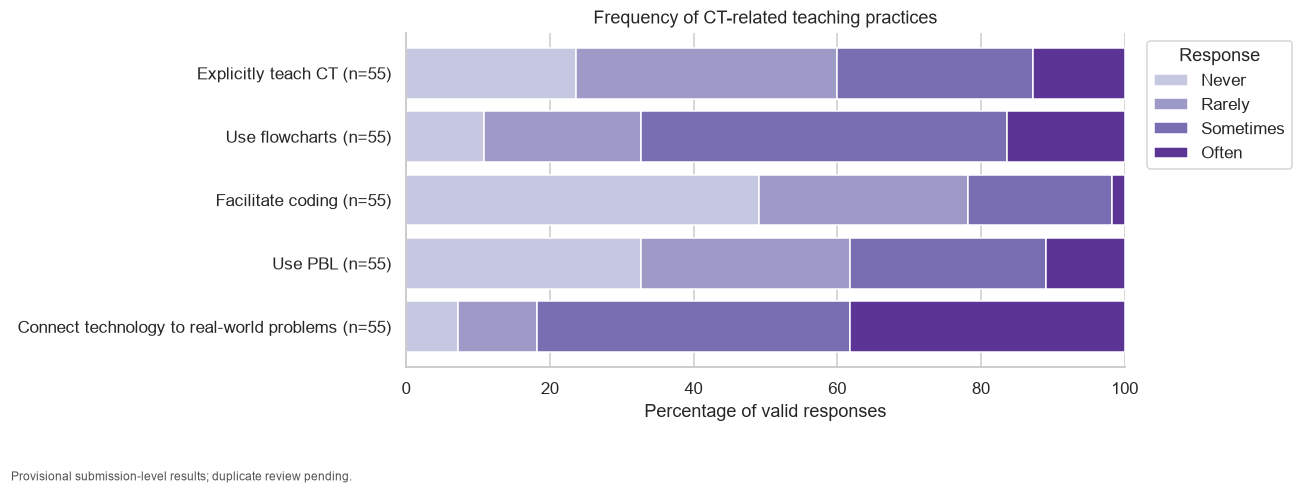

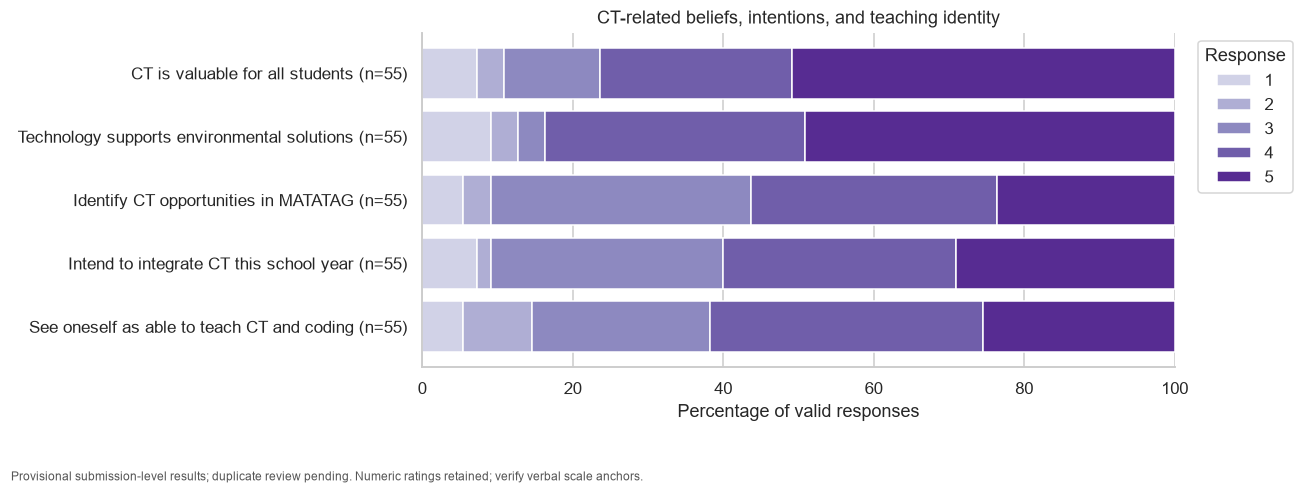

,item,valid_n,missing_n,median
0,CT is valuable for all students,55,0,5.0
1,Technology supports environmental solutions,55,0,4.0
2,Identify CT opportunities in MATATAG,55,0,4.0
3,Intend to integrate CT this school year,55,0,4.0
4,See oneself as able to teach CT and coding,55,0,4.0


In [9]:
scale_chart(
    mapping=FREQUENCY,
    order=FREQUENCY_ORDER,
    title="Frequency of CT-related teaching practices",
    filename="teachers_teaching_frequency.png",
    table_key="teaching_frequency",
)

scale_chart(
    mapping=ATTITUDES,
    order=[1, 2, 3, 4, 5],
    title="CT-related beliefs, intentions, and teaching identity",
    filename="teachers_attitude_ratings.png",
    table_key="attitude_ratings",
    note="Numeric ratings retained; verify verbal scale anchors.",
)

tables["attitude_summary"] = pd.DataFrame([
    {
        "item": label,
        "valid_n": int(df[column].notna().sum()),
        "missing_n": int(df[column].isna().sum()),
        "median": df[column].median(),
    }
    for column, label in ATTITUDES.items()
])

display(tables["attitude_summary"])

### Teaching Practices and Attitudes

The teaching-frequency chart shows that connecting technology to
real-world problems was more common than facilitating coding activities.

Coding facilitation was concentrated in the "Never" and "Rarely"
categories. Explicit CT teaching was also more commonly reported in
these lower-frequency categories.

Meanwhile, the statement that CT is valuable for all students received
a median rating of 5. The other four attitude statements each had a
median rating of 4.

Together, these findings suggest a distinction between valuing CT and
regularly implementing coding or CT activities. Practical lesson
examples and supported classroom implementation may therefore be useful.

The numeric rating anchors should be confirmed before describing
specific scores as "Agree" or "Strongly agree". The medians also do not
mean that every respondent held the same view.

## 9. Report Confidence Responses Separately

The source confidence questions contain the wording
"After completing the summit".

Display these answers descriptively without calling them baseline
confidence, measured improvement, or confirmed post-event outcomes.

Clarification of the question timing is required for further
interpretation.

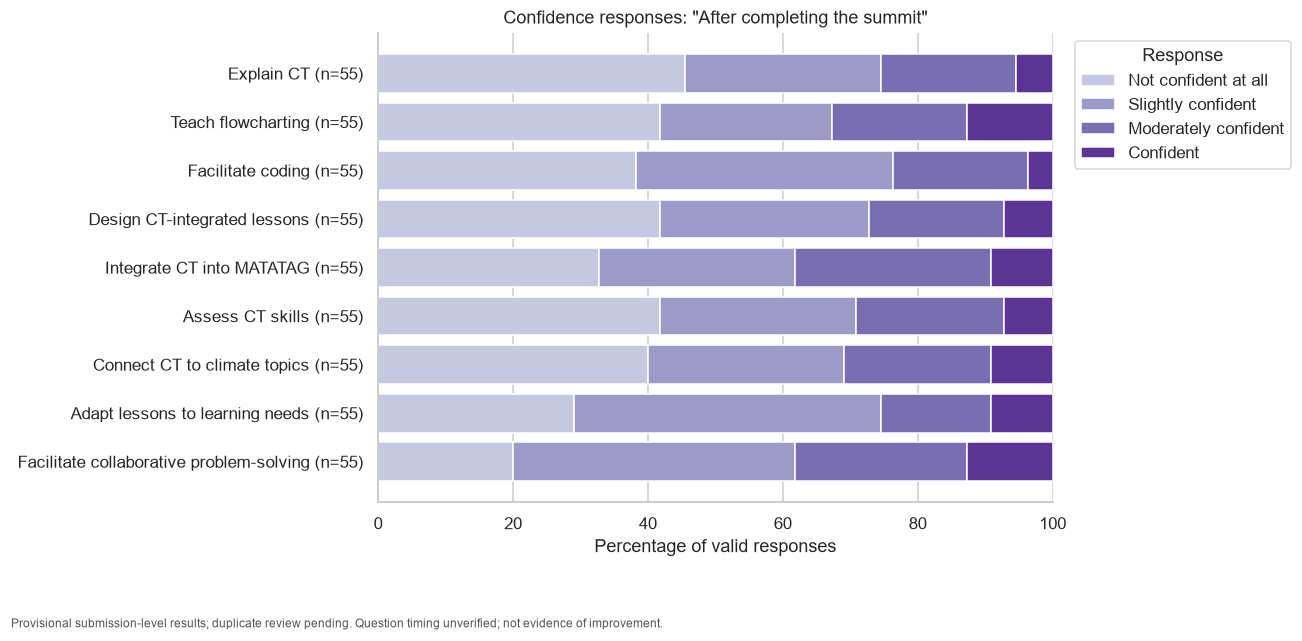

In [10]:
scale_chart(
    mapping=CONFIDENCE,
    order=CONFIDENCE_ORDER,
    title='Confidence responses: "After completing the summit"',
    filename="teachers_confidence_timing_unverified.png",
    table_key="confidence_responses",
    note="Question timing unverified; not evidence of improvement.",
)

### Confidence Interpretation Limitation

The confidence questions contain the phrase "After completing the
summit", although the workbook is labeled as a pre-event survey.

The available information does not establish whether these answers
represent expectations, post-event confidence, or a wording error.

Consequently, these responses are reported descriptively and are not
used as evidence of baseline confidence, measured improvement, or
the event's effectiveness. The survey administrator should clarify
the intended timing.

## 10. Examine Teaching Challenges and Environmental Concerns

Count selections for the questionnaire's fixed options.

Retain unusual or free-text additions in a separate review table.
Do not interpret a bare "Other" placeholder or "all" as a verified
selection of every option.

The denominator is the number of nonblank responses to each question.
A nonblank answer containing only an unspecified Other response remains
in that denominator.

Multiple selections are allowed, so percentages may exceed 100%.

,category,count,percent,valid_n,missing_n
2,Lack of training,48,87.272727,55,0
0,Limited devices,45,81.818182,55,0
1,Limited internet,42,76.363636,55,0
4,Lack of teaching resources,38,69.090909,55,0
3,Lack of classroom time,32,58.181818,55,0
6,Curriculum constraints,26,47.272727,55,0
5,Lack of confidence,25,45.454545,55,0


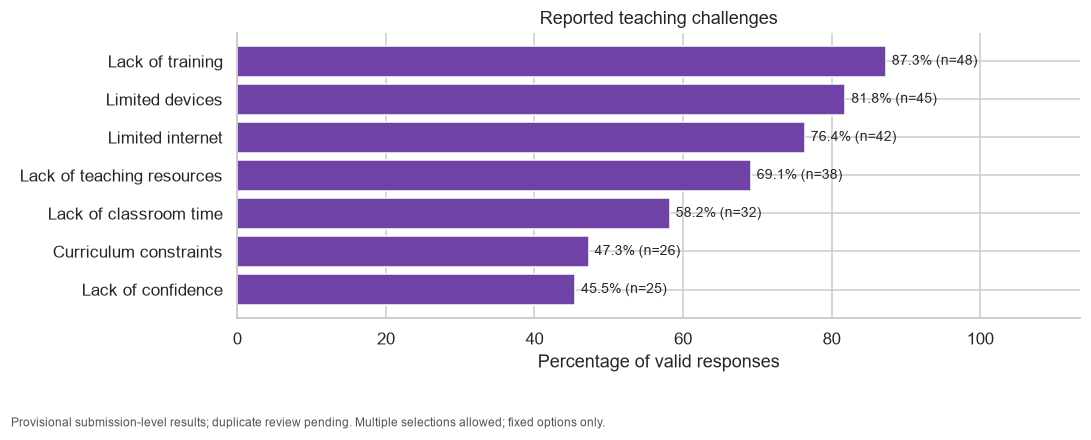

,category,count,percent,valid_n,missing_n
0,Flooding,50,90.909091,55,0
2,Extreme heat,48,87.272727,55,0
1,Typhoons,47,85.454545,55,0
4,Waste management,46,83.636364,55,0
6,Air pollution,32,58.181818,55,0
5,Plastic pollution,31,56.363636,55,0
3,Water shortage,18,32.727273,55,0


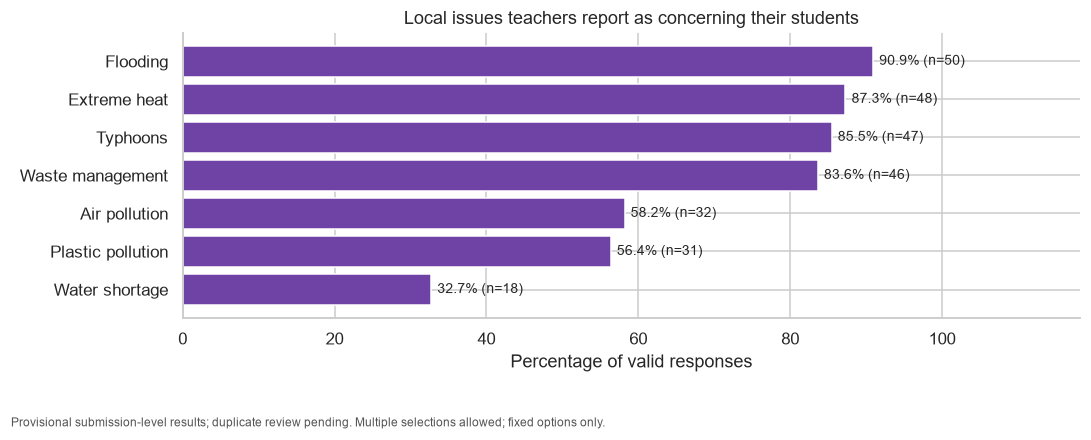

,category,count,percent,valid_n,missing_n
4,Waste management,50,90.909091,55,0
0,Flooding,47,85.454545,55,0
2,Extreme heat,32,58.181818,55,0
1,Typhoons,31,56.363636,55,0
5,Plastic pollution,31,56.363636,55,0
6,Air pollution,30,54.545455,55,0
3,Water shortage,23,41.818182,55,0


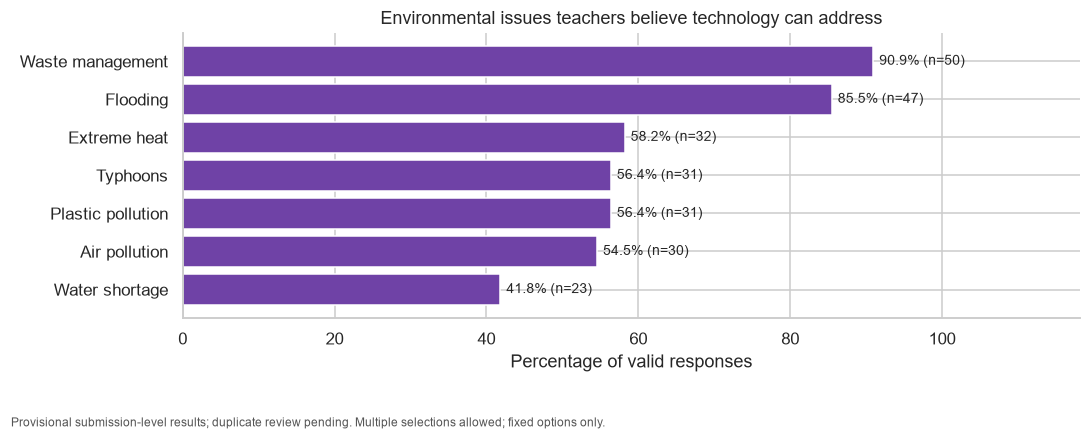

,response_id,question,unmatched_fragment,original_response,review_status
0,T0011,teaching_challenges,Other: __________,Other: __________,Pending
1,T0010,student_local_issues,Post-disaster diseases,"Flooding, Typhoons, Extreme heat, Water shorta...",Pending
2,T0010,student_local_issues,poor urban planning,"Flooding, Typhoons, Extreme heat, Water shorta...",Pending
3,T0007,tech_environment_uses,all,"Flooding, Typhoons, Extreme heat, Water shorta...",Pending
4,T0010,tech_environment_uses,Marine ecosystem,"Flooding, Typhoons, Extreme heat, Water shorta...",Pending


In [11]:
CHALLENGE_OPTIONS = [
    "Limited devices",
    "Limited internet",
    "Lack of training",
    "Lack of classroom time",
    "Lack of teaching resources",
    "Lack of confidence",
    "Curriculum constraints",
]

ENVIRONMENT_OPTIONS = [
    "Flooding",
    "Typhoons",
    "Extreme heat",
    "Water shortage",
    "Waste management",
    "Plastic pollution",
    "Air pollution",
]


def fixed_option_summary(column, options):
    canonical = {
        option.casefold(): option
        for option in options
    }

    counts = dict.fromkeys(options, 0)
    review = []
    valid_n = 0

    for index, value in df[column].items():
        value = normalize_text(value)

        if pd.isna(value):
            continue

        valid_n += 1
        selected = set()

        tokens = [
            token.strip()
            for token in value.split(",")
            if token.strip()
        ]

        for token in tokens:
            key = token.casefold()

            if key in canonical:
                selected.add(canonical[key])
            else:
                review.append({
                    "response_id": df.loc[index, "response_id"],
                    "question": column,
                    "unmatched_fragment": token,
                    "original_response": value,
                    "review_status": "Pending",
                })

        for option in selected:
            counts[option] += 1

    table = pd.DataFrame({
        "category": options,
        "count": [counts[option] for option in options],
    })

    table["percent"] = (
        table["count"] / valid_n * 100
        if valid_n
        else np.nan
    )

    table["valid_n"] = valid_n
    table["missing_n"] = len(df) - valid_n

    review_table = pd.DataFrame(
        review,
        columns=[
            "response_id",
            "question",
            "unmatched_fragment",
            "original_response",
            "review_status",
        ],
    )

    return table.sort_values("percent", ascending=False), review_table


checkbox_specs = [
    (
        "teaching_challenges",
        CHALLENGE_OPTIONS,
        "Reported teaching challenges",
    ),
    (
        "student_local_issues",
        ENVIRONMENT_OPTIONS,
        "Local issues teachers report as concerning their students",
    ),
    (
        "tech_environment_uses",
        ENVIRONMENT_OPTIONS,
        "Environmental issues teachers believe technology can address",
    ),
]

checkbox_reviews = []

for column, options, title in checkbox_specs:
    table, review = fixed_option_summary(column, options)

    tables[column] = table
    checkbox_reviews.append(review)

    display(table)

    horizontal_bar(
        table,
        title,
        f"teachers_{column}.png",
        note="Multiple selections allowed; fixed options only.",
    )

tables["checkbox_review"] = pd.concat(
    checkbox_reviews,
    ignore_index=True,
)

display(tables["checkbox_review"])

### Teaching Challenges

The most frequently selected challenges were lack of training
(48 submissions, 87.3%), limited devices (45, 81.8%), and limited
internet access (42, 76.4%).

| Challenge | Count | Percentage |
|---|---:|---:|
| Lack of training | 48 | 87.3% |
| Limited devices | 45 | 81.8% |
| Limited internet | 42 | 76.4% |
| Lack of teaching resources | 38 | 69.1% |
| Lack of classroom time | 32 | 58.2% |
| Curriculum constraints | 26 | 47.3% |
| Lack of confidence | 25 | 45.5% |

These findings suggest that professional learning should address both
instructional preparation and practical resource constraints.
Training alone may not resolve device, connectivity, and time barriers.

### Environmental Concerns

Flooding was the most frequently selected issue reported as concerning
students (50 submissions, 90.9%), followed by extreme heat (48, 87.3%),
typhoons (47, 85.5%), and waste management (46, 83.6%).

For issues respondents believed technology could help address,
waste management ranked first (50, 90.9%), followed by flooding
(47, 85.5%).

These topics provide relevant contexts for CT and technology activities,
such as waste-sorting decision rules or flood-warning flowcharts.
The survey does not establish that a particular technology intervention
will successfully address these problems.

All percentages use 55 nonblank responses per question. Multiple
selections were permitted, so percentages may exceed 100% when summed.

Five unmatched checkbox fragments remain pending review. These are
not necessarily five separate respondents. The charts summarize fixed
options and do not fully summarize free-text additions.

## 11. Compare CT Familiarity by Teaching Experience

Compare familiarity distributions within teaching-experience groups.

Display each group's valid sample size. Small groups can produce
unstable percentages, so this comparison is descriptive.

Differences between groups do not demonstrate that teaching experience
causes higher or lower CT familiarity.

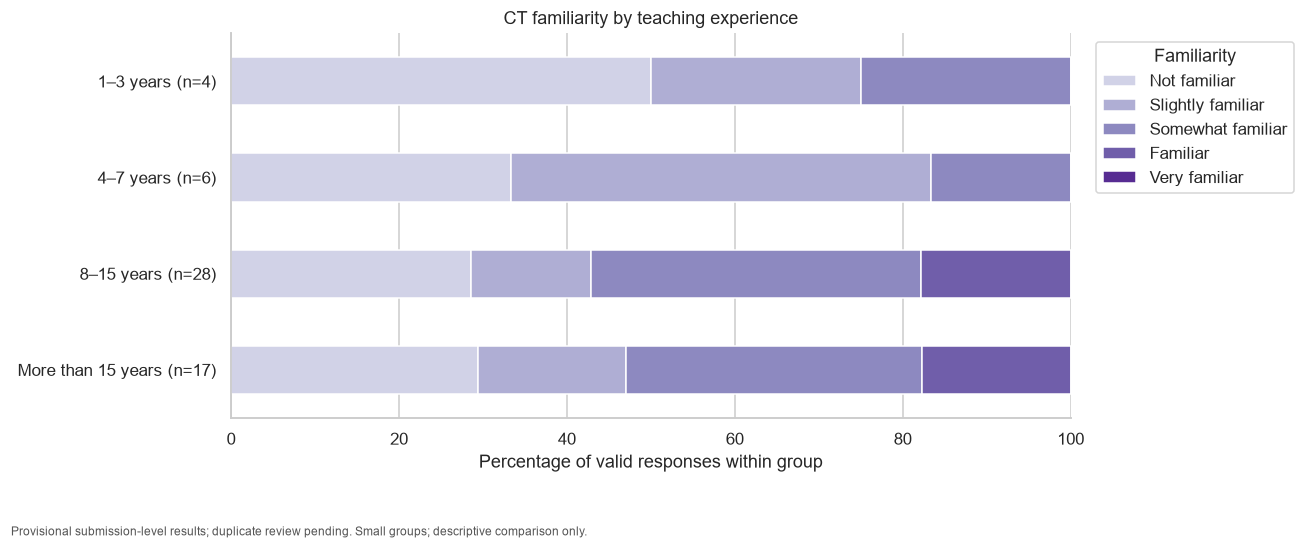

In [12]:
experience_order = [
    "1–3 years",
    "4–7 years",
    "8–15 years",
    "More than 15 years",
]

# Keep any unexpected categories visible.
experience_order += [
    value
    for value in df["teaching_experience"].dropna().unique()
    if value not in experience_order
]

comparison_counts = pd.crosstab(
    df["teaching_experience"],
    df["familiarity_ct"],
).reindex(
    index=experience_order,
    columns=FAMILIARITY_ORDER,
    fill_value=0,
)

group_n = comparison_counts.sum(axis=1)

comparison_percent = (
    comparison_counts.div(
        group_n.replace(0, np.nan),
        axis=0,
    ) * 100
)

tables["experience_ct_counts"] = comparison_counts
tables["experience_ct_percent"] = comparison_percent

plot_data = comparison_percent.loc[group_n > 0].copy()

plot_data.index = [
    f"{group} (n={int(group_n.loc[group])})"
    for group in plot_data.index
]

if not plot_data.empty:
    ax = plot_data.plot(
        kind="barh",
        stacked=True,
        figsize=(12, 5),
        color=sns.color_palette("Purples", 6)[1:],
    )

    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("Percentage of valid responses within group")
    ax.set_ylabel("")
    ax.set_title("CT familiarity by teaching experience")

    ax.legend(
        title="Familiarity",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )

    save_figure(
        ax.get_figure(),
        "teachers_experience_vs_ct_familiarity.png",
        note="Small groups; descriptive comparison only.",
    )

### CT Familiarity by Teaching Experience

Responses in the "Familiar" category appeared in the two groups with
at least eight years of teaching experience. However, both groups also
included responses indicating little or no familiarity.

The shorter-experience groups contained only four and six submissions.
Their percentages can therefore change substantially with a single
response.

This comparison is descriptive. It does not establish that teaching
experience causes greater CT familiarity, and the small, unequal groups
limit the strength of comparisons.

## 12. Prepare Written Responses for Theme Coding

Preserve original written answers.

Classify blank and punctuation-only answers, then create a manual
coding file for substantive responses about CT definitions, learning
goals, and teaching concerns.

Accommodation responses are excluded from the thematic reporting file.

A response may receive several themes. Theme assignments require
manual review.

In [16]:
TEXT_COLUMNS = [
    "ct_definition",
    "learning_goals",
    "teaching_concerns",
]

coding_rows = []
quality_rows = []

for column in TEXT_COLUMNS:
    normalized = df[column].map(normalize_text)

    substantive = normalized.map(
        lambda value: (
            False
            if pd.isna(value)
            else any(character.isalnum() for character in value)
        )
    )

    status = pd.Series(
        "Text present - review needed",
        index=df.index,
        dtype="string",
    )

    status.loc[normalized.isna()] = "Missing"
    status.loc[normalized.notna() & ~substantive] = "Punctuation only"

    df[f"{column}_status"] = status
    df[f"{column}_analysis"] = normalized.where(substantive, pd.NA)

    for label, count in status.value_counts().items():
        quality_rows.append({
            "question": column,
            "status": label,
            "count": int(count),
        })

    for index in df.index[substantive]:
        coding_rows.append({
            "response_id": df.loc[index, "response_id"],
            "question": column,
            "response_text": normalized.loc[index],
            "themes": "",
            "reviewed": False,
        })

tables["written_response_quality"] = pd.DataFrame(quality_rows)

coding_path = TABLES / "teachers_theme_coding.csv"
coding_template = pd.DataFrame(coding_rows)

# Preserve previously entered manual coding.
if not coding_path.exists():
    coding_template.to_csv(
        coding_path,
        index=False,
        encoding="utf-8-sig",
    )
    print("Created:", coding_path.name)
else:
    print("Existing coding file preserved.")

display(tables["written_response_quality"])

Existing coding file preserved.


,question,status,count
0,ct_definition,Text present - review needed,55
1,learning_goals,Text present - review needed,55
2,teaching_concerns,Text present - review needed,55


| Question | Example themes |
|---|---|
| Learning goals | CT knowledge, coding skills, classroom activities, curriculum integration |
| Teaching concerns | Limited skills, devices, internet access, classroom time, learner differences |
| CT definitions | Decomposition, patterns, step-by-step problem solving, unclear understanding |

## 13. Summarize Manually Reviewed Themes

Summarize only records marked as reviewed in the coding file.

The denominator is the number of reviewed responses for each question.
Theme percentages may exceed 100% because multiple themes are allowed.

Unreviewed responses are not represented in these charts.

In [14]:
coding = pd.read_csv(
    coding_path,
    keep_default_na=False,
    dtype={"response_id": "string"},
)

coding = coding.loc[
    coding["response_id"].isin(df["response_id"])
].copy()

if coding.duplicated(["response_id", "question"]).any():
    raise ValueError("Duplicate response/question rows in the coding file.")

coding["reviewed_bool"] = (
    coding["reviewed"]
    .astype("string")
    .str.strip()
    .str.casefold()
    .isin(["true", "yes", "1"])
)

for question in TEXT_COLUMNS:
    reviewed = coding.loc[
        coding["question"].eq(question)
        & coding["reviewed_bool"]
    ]

    if reviewed.empty:
        print(f"{question}: no reviewed themes yet.")
        continue

    tokens = []

    for response in reviewed["themes"]:
        selected_themes = {
            theme.strip()
            for theme in str(response).split(";")
            if theme.strip()
        }

        tokens.extend(selected_themes)

    if not tokens:
        print(f"{question}: reviewed rows have no theme labels.")
        continue

    counts = pd.Series(tokens).value_counts()

    table = counts.rename_axis(
        "category"
    ).reset_index(name="count")

    table["percent"] = table["count"] / len(reviewed) * 100
    table["reviewed_n"] = len(reviewed)

    tables[f"themes_{question}"] = table

    horizontal_bar(
        table,
        f"Reviewed teacher themes: {question}",
        f"teachers_themes_{question}.png",
        note="Reviewed responses only; multiple themes allowed.",
    )

ct_definition: no reviewed themes yet.
learning_goals: no reviewed themes yet.
teaching_concerns: no reviewed themes yet.


### Written-Response Review Status

All 55 responses to each of the three written questions contain text.
This does not establish that every response is relevant, meaningful,
or correct.

The automated check distinguishes missing and punctuation-only answers
from answers containing letters or numbers. Interpretation requires
manual review.

No responses have yet been marked as reviewed in the theme-coding file.
Therefore, the example themes remain proposed categories, and no
thematic findings are reported.

## 14. Export Analysis Tables and the Standardized Dataset

Save the standardized teacher dataset separately from the original
cleaned workbook.

Export analysis tables, review tables, and methodological notes.

Review tables contain identifiers and should be excluded from public
reports. Figures contain aggregate results.

In [15]:
tables["quality_summary"] = pd.DataFrame({
    "metric": [
        "Original submissions",
        "Confirmed exclusions",
        "Retained submissions",
        "Unresolved duplicate-candidate rows",
        "Rows missing school name or cluster",
        "Schools with multiple reported clusters",
    ],
    "count": [
        original_n,
        len(tables["excluded_submissions"]),
        len(df),
        int(df["possible_duplicate"].sum()),
        int(df["missing_school"].sum()),
        len(conflicting_schools),
    ],
})

tables["analysis_notes"] = pd.DataFrame([
    {
        "item": "Unit of analysis",
        "details": "Survey submissions; unresolved duplicate candidates retained.",
    },
    {
        "item": "Percentages",
        "details": "Use valid responses to each question as the denominator.",
    },
    {
        "item": "Checkbox questions",
        "details": (
            "Multiple selections allowed. Fixed options counted separately; "
            "unmatched text exported for review."
        ),
    },
    {
        "item": "Confidence timing",
        "details": (
            "Source wording says After completing the summit. "
            "Timing unverified; not interpreted as improvement."
        ),
    },
    {
        "item": "Small groups",
        "details": "Group comparisons are descriptive and may be unstable.",
    },
    {
        "item": "Written themes",
        "details": "Only manually reviewed responses contribute to theme charts.",
    },
])

standardized_path = CLEANED / "teachers_pre_event_standardized.xlsx"
tables_path = TABLES / "teachers_analysis_tables.xlsx"


def format_export(writer):
    from openpyxl.styles import Font, PatternFill, Alignment
    from openpyxl.utils import get_column_letter

    for ws in writer.book.worksheets:
        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions
        ws.sheet_view.showGridLines = False

        for cell in ws[1]:
            cell.fill = PatternFill("solid", fgColor="4C286B")
            cell.font = Font(bold=True, color="FFFFFF")
            cell.alignment = Alignment(
                wrap_text=True,
                vertical="center",
            )

        ws.row_dimensions[1].height = 42

        for column_index in range(1, ws.max_column + 1):
            values = [
                str(ws.cell(row, column_index).value or "")
                for row in range(1, ws.max_row + 1)
            ]

            width = min(
                65,
                max(16, max(map(len, values), default=0) + 2),
            )

            ws.column_dimensions[
                get_column_letter(column_index)
            ].width = width

        for row in ws.iter_rows(min_row=2):
            for cell in row:
                cell.alignment = Alignment(
                    vertical="top",
                    wrap_text=True,
                )

                # Preserve survey text beginning with "=" as literal text.
                if (
                    isinstance(cell.value, str)
                    and cell.value.startswith("=")
                ):
                    cell.data_type = "s"


with pd.ExcelWriter(
    standardized_path,
    engine="openpyxl",
) as writer:
    df.to_excel(
        writer,
        sheet_name="Standardized Data",
        index=False,
    )
    format_export(writer)

with pd.ExcelWriter(
    tables_path,
    engine="openpyxl",
) as writer:
    for name, table in tables.items():
        include_index = not isinstance(table.index, pd.RangeIndex)

        table.to_excel(
            writer,
            sheet_name=name[:31],
            index=include_index,
        )

    format_export(writer)

display(tables["quality_summary"])

print("Standardized data:", standardized_path)
print("Analysis tables:", tables_path)
print("Figures:", FIGURES)

,metric,count
0,Original submissions,55
1,Confirmed exclusions,0
2,Retained submissions,55
3,Unresolved duplicate-candidate rows,2
4,Rows missing school name or cluster,3
5,Schools with multiple reported clusters,2


Standardized data: C:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\SEPTEMBER _6_DATA\data\cleaned\teachers_pre_event_standardized.xlsx
Analysis tables: C:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\SEPTEMBER _6_DATA\outputs\tables\teachers\teachers_analysis_tables.xlsx
Figures: C:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\SEPTEMBER _6_DATA\outputs\figures\teachers


## Overall Findings and Conclusions

This analysis summarizes the responses of 55 teacher survey submissions. Most respondents reported substantial teaching experience: 45 (81.8%) had at least eight years of experience. Science was the most frequently reported subject area.

Despite their teaching experience, respondents reported limited familiarity with several computing concepts. For block-based coding, 36 respondents (65.5%) selected “Not familiar” or “Slightly familiar”; for text-based coding, 38 (69.1%) selected these categories. Additionally, 49 respondents (89.1%) reported no prior experience facilitating the type of project described in the survey.

AI was the most frequently reported technology used with students, although only 13 respondents (23.6%) reported classroom use. Classroom use of the other listed technologies was less common. Coding activities were also infrequent: 43 respondents (78.2%) reported using them “Never” or “Rarely.” In contrast, 45 respondents (81.8%) reported incorporating real-world problems “Sometimes” or “Often.”

Attitude ratings suggest generally positive views toward computational thinking and its educational applications. The median rating for the value of computational thinking was 5 out of 5, while the other attitude items had median ratings of 4. At the group level, these positive ratings coexist with limited reported coding experience and infrequent implementation of some practices. These summaries do not establish whether individual respondents with higher attitude ratings implement these practices more frequently.

The most frequently selected teaching challenges were lack of training (87.3%), limited devices (81.8%), and limited internet access (76.4%). These findings suggest that practical introductory training, accessible teaching materials, and activities suitable for limited-resource classrooms would address commonly reported needs.

Flooding (90.9%) and extreme heat (87.3%) were the most frequently selected local environmental issues affecting students. Waste management (90.9%) and flooding (85.5%) were the most frequently selected issues that respondents believed technology could help address. These topics provide relevant starting points for locally grounded classroom activities.

The findings remain provisional. Two submissions were flagged as possible duplicates, three lacked school information, and some school–cluster assignments require verification. Open-ended responses still require manual thematic review. Confidence questions referring to “after completing the summit” have uncertain timing and should not be interpreted as evidence of baseline confidence or improvement caused by the event.

Overall, the survey identifies potential training needs and locally relevant teaching topics within this respondent group. The results describe self-reported responses and should not be generalized to all teachers or interpreted as evidence of actual classroom performance. Any subsequent machine learning analysis should be treated as exploratory because of the small sample.

## Target Distribution Findings

The proposed prediction target is teachers’ self-reported intention to integrate computational thinking, represented by `integration_intention`.

For exploratory binary classification, the original ratings are grouped as follows:

| Target group | Original ratings | Submissions | Percentage |
|---|---|---:|---:|
| Lower or moderate reported intention | 1–3 | 22 | 40.0% |
| Higher reported intention | 4–5 | 33 | 60.0% |
| **Total** | **1–5** | **55** | **100.0%** |

There are no missing target responses among the 55 submissions. Higher reported intention is the larger group, with 33 submissions (60.0%), compared with 22 (40.0%) in the lower or moderate group. Ratings of 1–3 should not be interpreted as unwillingness to integrate computational thinking.

These counts describe the dataset before modeling exclusions. The target distribution must be recalculated after resolving or excluding possible duplicates and handling missing school information.

Both target groups are represented, allowing an exploratory classification exercise. However, the small sample limits the reliability of model evaluation. A classifier that always predicts the larger group would achieve 60.0% accuracy on this full dataset, so accuracy alone would be insufficient to demonstrate useful prediction. Evaluation should also include balanced accuracy, macro F1, and recall for each group.

The model would estimate reported integration intention from other survey responses collected at the same time. It would not establish whether teachers later implemented computational thinking or whether the summit changed their behavior. Grouping the ratings into two categories also removes distinctions within the original five-point scale.

## Readiness for Exploratory Prediction

The standardized dataset can support a small exploratory
supervised-learning exercise, but it is not sufficient to establish
reliable predictions for the wider teacher population.

The current dataset contains 55 submissions, including two unresolved
duplicate candidates. Duplicate decisions should be resolved before
modeling. If unresolved candidates are excluded temporarily, the
exclusion and its effect on the modeling sample must be documented.

Three submissions lack school information. A school-grouped evaluation
requires verified school membership or documented exclusion of those
records. Inconsistent cluster numbers do not prevent grouping by a
verified school name.

The confidence variables beginning with `after_summit_conf_` will be
excluded while their timing remains uncertain.

Unreviewed written-response themes will not be used as predictors.
Their incomplete coding does not prevent modeling with other verified
structured variables.

Before training, define one prediction target, examine its class
distribution after exclusions, select a small predictor set, and
compare performance with a simple baseline.

Any model will predict a reported survey response, not actual future
teaching behavior or the effect of the summit.

## Preliminary Target Check: Reported Intention to Integrate CT

Inspect the original 1–5 distribution of integration intention.

For a possible binary experiment, ratings 4–5 would form one class
and ratings 1–3 the other. Ratings 1–3 must not be labeled as
"unwilling to integrate CT".

This is a candidate target, not a finalized modeling decision.
Counts must be checked again after modeling exclusions.

In [17]:
target = pd.to_numeric(
    df["integration_intention"],
    errors="coerce",
)

invalid = (
    df["integration_intention"].notna()
    & ~target.isin([1, 2, 3, 4, 5])
)

if invalid.any():
    raise ValueError("Review invalid integration-intention ratings.")

valid = target.loc[target.isin([1, 2, 3, 4, 5])]

rating_counts = valid.value_counts().reindex(
    [1, 2, 3, 4, 5],
    fill_value=0,
)

display(
    rating_counts.rename_axis("rating").reset_index(name="count")
)

candidate_classes = pd.DataFrame({
    "candidate_class": ["Ratings 1–3", "Ratings 4–5"],
    "count": [
        int(valid.le(3).sum()),
        int(valid.ge(4).sum()),
    ],
})

candidate_classes["percent"] = (
    candidate_classes["count"] / len(valid) * 100
    if len(valid)
    else np.nan
)

display(candidate_classes)
print("Missing target answers:", int(target.isna().sum()))
print("These counts are before modeling exclusions.")

,rating,count
0,1,4
1,2,1
2,3,17
3,4,17
4,5,16


,candidate_class,count,percent
0,Ratings 1–3,22,40.0
1,Ratings 4–5,33,60.0


Missing target answers: 0
These counts are before modeling exclusions.
